# Clasificación de animales con CNN y Transfer Learning (PyTorch)

**Dataset**: [Kaggle – Animal Data (likhon148)](https://www.kaggle.com/datasets/likhon148/animal-data)

### Objetivos
1. Descargar el dataset con `kagglehub` y prepararlo (split estratificado train / val / test).
2. Crear y entrenar una **CNN desde cero** con imágenes redimensionadas a **32x32**.
3. Aplicar **Transfer Learning** con dos arquitecturas preentrenadas en ImageNet: **ResNet18** (a 128x128 y a 32x32) y **AlexNet** (a 128x128).
4. **Comparar** los cuatro modelos (accuracy, balanced accuracy, macro-F1, matriz de confusión, tiempos, parámetros).
5. **Guardar los pesos** de los cuatro modelos y un archivo de configuración para usarlos en la app **NNApp** (FastAPI + Streamlit).

> **Nota sobre los tamaños de entrada:** la CNN se entrena a 32x32 como pide la actividad. AlexNet **no puede procesar imágenes de 32x32**
> (sus capas de pooling reducen el mapa de características a menos de 1 píxel), por eso AlexNet y ResNet18 usan un tamaño mayor
> (`TL_IMG_SIZE`, 128 por defecto). Además, ResNet18 se entrena también a 32x32 para compararlo con la CNN a igual resolución.
> Esto se tiene en cuenta en la comparación.

Equipo integrado por:

- Ana María Tique, 2220241069
- Yaritxa Duarte, 2220241061
- Manuel Posada, 2220241121

## 1. Instalación e importación de librerías

In [ ]:
# torch y torchvision tienen que estar instalados (recomendable o colab para ejecutarlo correctamente)
!pip -q install kagglehub scikit-learn seaborn matplotlib pandas pillow

In [ ]:
import os, glob, json, time, random, shutil, math
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from IPython.display import display

import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             balanced_accuracy_score, f1_score, accuracy_score)

import kagglehub

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Dispositivo:', device)

plt.style.use('seaborn-v0_8')
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.size'] = 10

Dispositivo: cuda


## 2. Configuración general
- `CNN_IMG_SIZE = 32`: tamaño exigido para la CNN desde cero (también se usa en el experimento de ResNet18 a 32x32).
- `TL_IMG_SIZE = 128`: tamaño para ResNet18 y AlexNet (AlexNet necesita al menos ~64 px).
- Se usa la normalización de ImageNet en todos los modelos (los preentrenados la necesitan; a la CNN no le afecta).

In [ ]:
CNN_IMG_SIZE = 32
TL_IMG_SIZE  = 128
BATCH_SIZE   = 64
NUM_WORKERS  = 2
MODELS_DIR   = 'models'
os.makedirs(MODELS_DIR, exist_ok=True)

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

## 3. Descarga del dataset (Kaggle) y localización de las clases
`kagglehub` descarga el dataset en una carpeta local. Como no conocemos de antemano la estructura exacta de carpetas,
buscamos automáticamente el directorio que contiene **una subcarpeta por clase** con imágenes dentro.

In [ ]:
path = kagglehub.dataset_download("likhon148/animal-data")
print("Path to dataset files:", path)

100%|██████████| 36.3M/36.3M [00:00<00:00, 74.7MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/likhon148/animal-data/versions/1


In [ ]:
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

def find_class_root(base):
    """Devuelve el directorio con más subcarpetas que contienen imágenes (una por clase)."""
    best, best_n = None, 0
    for dirpath, dirnames, _ in os.walk(base):
        n = 0
        for d in dirnames:
            full = os.path.join(dirpath, d)
            if any(os.path.splitext(f)[1].lower() in IMG_EXT for f in os.listdir(full)):
                n += 1
        if n > best_n:
            best, best_n = dirpath, n
    return best, best_n

DATA_ROOT, n_found = find_class_root(path)
print('DATA_ROOT:', DATA_ROOT)
print('Carpetas de clase encontradas:', n_found)
assert DATA_ROOT is not None, 'No se encontraron carpetas de clases con imágenes'

DATA_ROOT: /root/.cache/kagglehub/datasets/likhon148/animal-data/versions/1/animal_data
Carpetas de clase encontradas: 15


## 4. Exploración del dataset

Total de imágenes: 1944 | Clases: 15
['Bear', 'Bird', 'Cat', 'Cow', 'Deer', 'Dog', 'Dolphin', 'Elephant', 'Giraffe', 'Horse', 'Kangaroo', 'Lion', 'Panda', 'Tiger', 'Zebra']


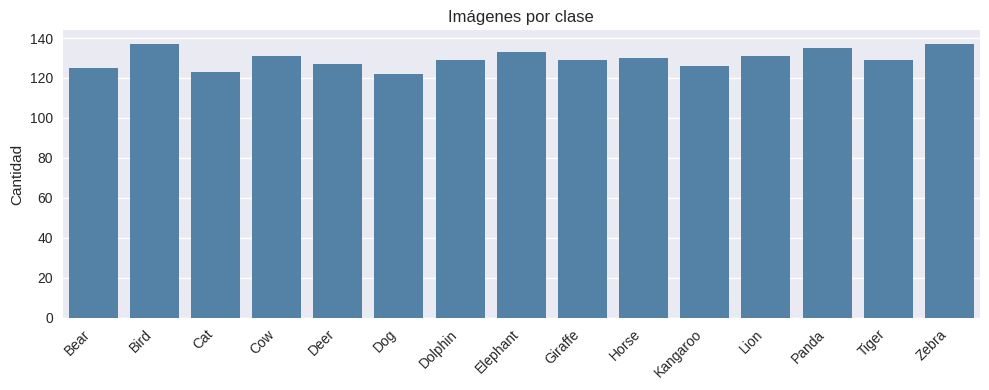

Tamaños originales más comunes: [((224, 224), 300)]


In [ ]:
full_ds = datasets.ImageFolder(DATA_ROOT)          # sin transformaciones: solo para explorar y hacer el split
class_names = full_ds.classes
NUM_CLASSES = len(class_names)
targets = np.array(full_ds.targets)

print(f'Total de imágenes: {len(full_ds)} | Clases: {NUM_CLASSES}')
print(class_names)

counts = np.bincount(targets, minlength=NUM_CLASSES)
plt.figure(figsize=(10, 4))
sns.barplot(x=class_names, y=counts, color='steelblue')
plt.xticks(rotation=45, ha='right')
plt.title('Imágenes por clase')
plt.ylabel('Cantidad')
plt.tight_layout()
plt.show()

# Tamaños originales (muestra de hasta 300 imágenes)
sample_paths = random.sample(full_ds.samples, min(300, len(full_ds)))
print('Tamaños originales más comunes:', Counter(Image.open(p).size for p, _ in sample_paths).most_common(5))

**Interpretación:** el dataset tiene 1944 imágenes repartidas en 15 clases de animales (Bear, Bird, Cat, Cow, Deer, Dog, Dolphin, Elephant, Giraffe, Horse, Kangaroo, Lion, Panda, Tiger y Zebra).

En el gráfico de barras todas las clases están entre 120 y 140: Dog es la clase más pequeña (cerca de 122) y Bird y Zebra las más grandes (cerca de 137). La diferencia entre la mayor y la menor es de unas 15 imágenes, así que el dataset está prácticamente balanceado.

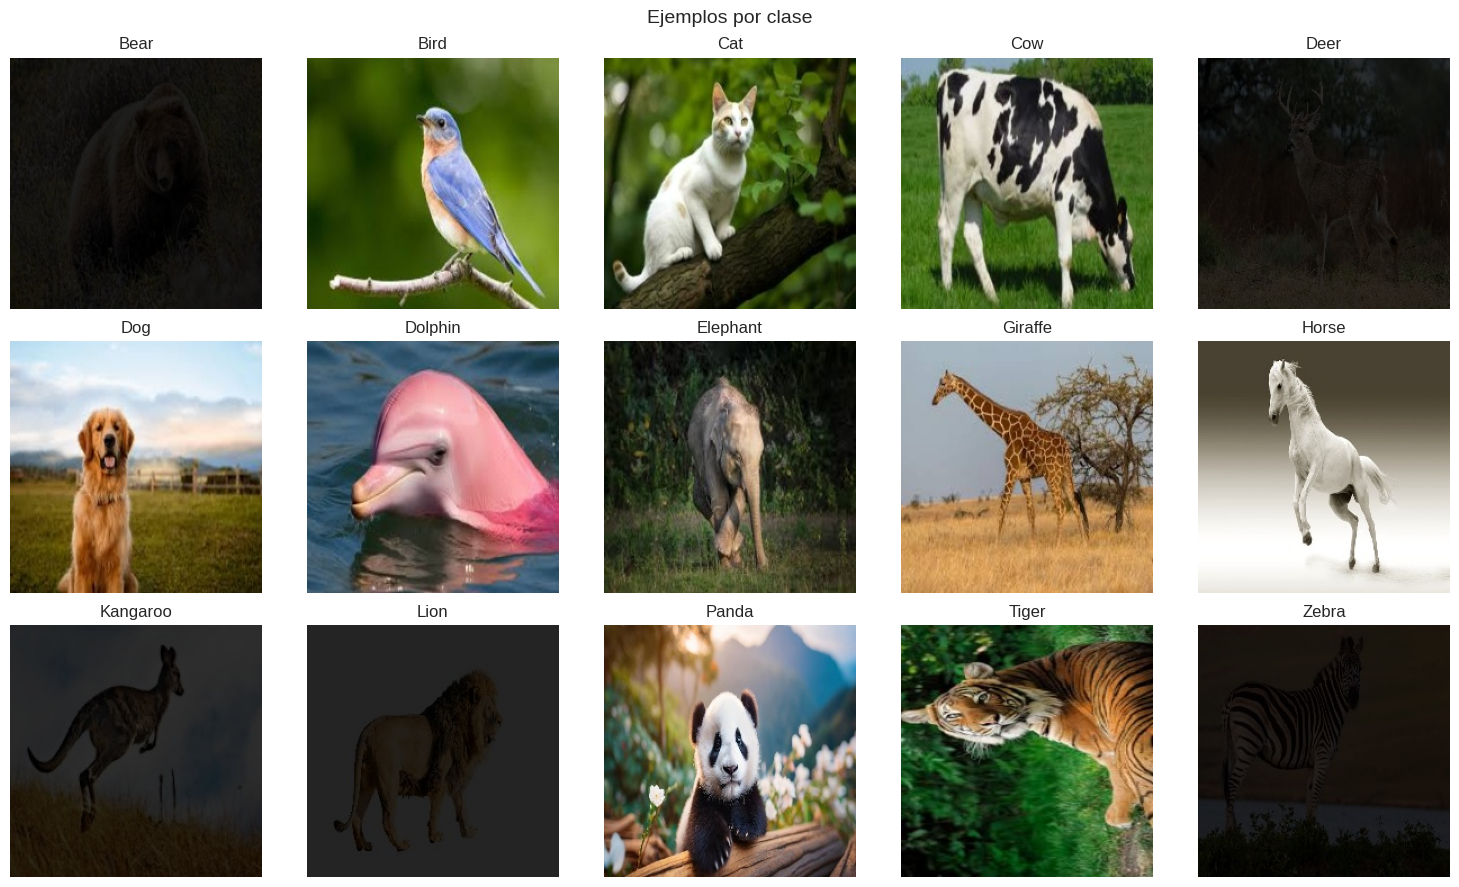

In [ ]:
# Una imagen de ejemplo por clase
ncols = 5
nrows = math.ceil(NUM_CLASSES / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 3 * nrows))
axes = np.array(axes).reshape(-1)
rng = random.Random(SEED)
for c, cls in enumerate(class_names):
    i = rng.choice(np.where(targets == c)[0])
    axes[c].imshow(Image.open(full_ds.samples[i][0]).convert('RGB'))
    axes[c].set_title(cls)
for ax in axes:
    ax.axis('off')
fig.suptitle('Ejemplos por clase', fontsize=14)
plt.tight_layout()
plt.show()

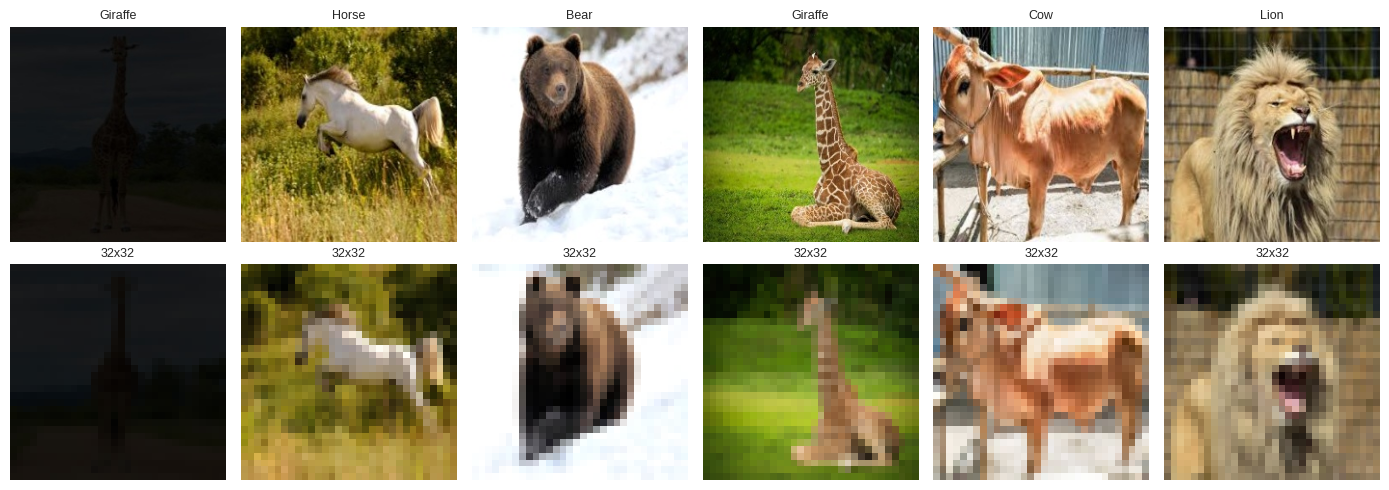

In [ ]:
# ¿Cómo "ve" la CNN las imágenes a 32x32? (original vs. redimensionada)
idxs = rng.sample(range(len(full_ds)), 6)
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for j, i in enumerate(idxs):
    img = Image.open(full_ds.samples[i][0]).convert('RGB')
    axes[0, j].imshow(img); axes[0, j].set_title(class_names[targets[i]], fontsize=9)
    axes[1, j].imshow(img.resize((CNN_IMG_SIZE, CNN_IMG_SIZE)), interpolation='nearest')
    axes[1, j].set_title(f'{CNN_IMG_SIZE}x{CNN_IMG_SIZE}', fontsize=9)
    axes[0, j].axis('off'); axes[1, j].axis('off')
plt.tight_layout()
plt.show()

**Interpretación:** al pasar de 224x224 a 32x32 se pierde casi todo el detalle fino. En la fila de abajo se conservan la silueta, los colores y el fondo (el caballo blanco sobre el pasto, el oso oscuro sobre la nieve), pero desaparecen las texturas y los rasgos pequeños (las manchas de la jirafa, la melena del león, el pelaje de la vaca).

Esto nos da una hipótesis: a 32px los modelos se apoyarán más en color, silueta y fondo que en rasgos finos, así que esperamos más confusiones entre animales de forma y color parecidos (por ejemplo Cow/Horse/Deer, o Lion/Tiger si el color se confunde).

## 5. Split estratificado y DataLoaders
Se crea un split **70 % train / 15 % validación / 15 % test** estratificado por clase (mismos índices para todos los modelos,
así la comparación es justa). Solo el set de entrenamiento lleva *data augmentation*.

In [ ]:
idx_all = np.arange(len(targets))
train_idx, tmp_idx = train_test_split(idx_all, test_size=0.30, stratify=targets, random_state=SEED)
val_idx, test_idx  = train_test_split(tmp_idx, test_size=0.50, stratify=targets[tmp_idx], random_state=SEED)
print(f'Train: {len(train_idx)} | Val: {len(val_idx)} | Test: {len(test_idx)}')

def make_loaders(img_size):
    norm = transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
    train_tf = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(15),
        transforms.ColorJitter(brightness=0.2, contrast=0.2),
        transforms.ToTensor(), norm])
    eval_tf = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(), norm])

    ds_train = Subset(datasets.ImageFolder(DATA_ROOT, transform=train_tf), train_idx)
    ds_val   = Subset(datasets.ImageFolder(DATA_ROOT, transform=eval_tf),  val_idx)
    ds_test  = Subset(datasets.ImageFolder(DATA_ROOT, transform=eval_tf),  test_idx)

    g = torch.Generator().manual_seed(SEED)
    pin = device.type == 'cuda'
    return {
        'train': DataLoader(ds_train, batch_size=BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS, generator=g, pin_memory=pin),
        'val':   DataLoader(ds_val,   batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin),
        'test':  DataLoader(ds_test,  batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin),
    }

loaders_cnn = make_loaders(CNN_IMG_SIZE)   # 32x32  -> CNN desde cero y ResNet18 (32px)
loaders_tl  = make_loaders(TL_IMG_SIZE)    # 128x128 -> ResNet18 y AlexNet

xb, yb = next(iter(loaders_cnn['train']))
print('Batch CNN:', xb.shape, '| Batch TL:', next(iter(loaders_tl['train']))[0].shape)

Train: 1360 | Val: 292 | Test: 292
Batch CNN: torch.Size([64, 3, 32, 32]) | Batch TL: torch.Size([64, 3, 128, 128])


**Interpretación:** de las 1944 imágenes quedaron 1360 para entrenar, 292 para validar y 292 para test. Eso es 69.96 %, 15.02 % y 15.02 %.

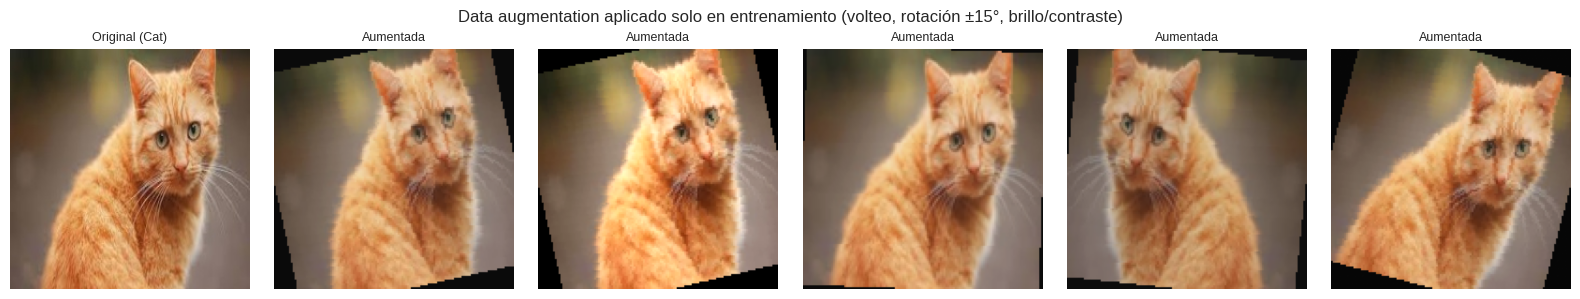

In [ ]:
# Visualizar el data augmentation del set de entrenamiento (original + 5 versiones aleatorias)
mean_t = torch.tensor(IMAGENET_MEAN).view(3, 1, 1); std_t = torch.tensor(IMAGENET_STD).view(3, 1, 1)
train_base = loaders_tl['train'].dataset.dataset          # ImageFolder con las transformaciones de entrenamiento
i = int(train_idx[0])
orig = Image.open(train_base.samples[i][0]).convert('RGB')

fig, axes = plt.subplots(1, 6, figsize=(16, 3))
axes[0].imshow(orig); axes[0].set_title(f'Original ({class_names[targets[i]]})', fontsize=9)
for ax in axes[1:]:
    x = train_base.transform(orig)                          # cada llamada da una versión distinta
    ax.imshow((x * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy())
    ax.set_title('Aumentada', fontsize=9)
for ax in axes: ax.axis('off')
plt.suptitle('Data augmentation aplicado solo en entrenamiento (volteo, rotación ±15°, brillo/contraste)')
plt.tight_layout(); plt.show()

**Interpretación:** la imagen original es un gato naranja y las cinco versiones aumentadas son claramente distintas entre sí, aunque sigue siendo reconociblemente el mismo gato. Lo que se observa:

**Rotaciones:** cada versión aparece inclinada un poco hacia un lado distinto, dentro del rango de ±15°.

**Volteo horizontal:** al menos una de las versiones (la cuarta) parece estar en espejo respecto de la original, lo que coincide con el RandomHorizontalFlip.

**Bordes negros:** al rotar, las esquinas quedan sin información y se rellenan con negro. Es un efecto secundario normal de RandomRotation. No debería afectar mucho, porque ocurre al azar y solo en entrenamiento, pero el modelo ve algunos bordes artificiales que no existen en test.

**Brillo y contraste:** los cambios son sutiles (±20 %), así que se notan poco a simple vista. Hay pequeñas diferencias de tono entre las versiones.

## 6. Definición de los modelos
Las arquitecturas se escriben en un archivo `model_defs.py` (con `%%writefile`) para poder **reutilizar exactamente el mismo código en la app NNApp**
al cargar los pesos guardados.

- **CNN desde cero**: 4 bloques Conv-BatchNorm-ReLU-MaxPool, Global Average Pooling y 2 capas densas (sin softmax: la pérdida `CrossEntropyLoss` ya lo incluye).
- **ResNet18 (Transfer Learning)**: pesos de ImageNet, backbone congelado, se reemplaza la capa `fc` por una nueva para nuestras clases. Se entrena con imágenes de 128x128 y también de 32x32 (misma arquitectura: claves `resnet18` y `resnet18_32`).
- **AlexNet (Transfer Learning)**: pesos de ImageNet, todo congelado, se reemplaza la última capa del clasificador.

In [ ]:
%%writefile model_defs.py
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models


class CNNBaseline(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1);   self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1);  self.bn2 = nn.BatchNorm2d(64)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1); self.bn3 = nn.BatchNorm2d(128)
        self.conv4 = nn.Conv2d(128, 256, kernel_size=3, padding=1); self.bn4 = nn.BatchNorm2d(256)
        self.pool = nn.MaxPool2d(2, 2)
        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        self.fc1 = nn.Linear(256, 256)
        self.bn_fc = nn.BatchNorm1d(256)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, num_classes)   # sin softmax: lo incluye CrossEntropyLoss

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))
        x = self.pool(F.relu(self.bn4(self.conv4(x))))
        x = torch.flatten(self.gap(x), 1)
        x = self.dropout(x)
        x = F.relu(self.bn_fc(self.fc1(x)))
        x = self.dropout(x)
        return self.fc2(x)


def build_resnet18(num_classes, pretrained=True):
    weights = models.ResNet18_Weights.DEFAULT if pretrained else None
    m = models.resnet18(weights=weights)
    for p in m.parameters():
        p.requires_grad = False                       # congelar backbone
    m.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.fc.in_features, num_classes))
    return m


def build_alexnet(num_classes, pretrained=True):
    weights = models.AlexNet_Weights.DEFAULT if pretrained else None
    m = models.alexnet(weights=weights)
    for p in m.parameters():
        p.requires_grad = False                       # congelar todo
    m.classifier[6] = nn.Linear(m.classifier[6].in_features, num_classes)   # nueva capa de salida
    return m


def build_model(arch, num_classes, pretrained=True):
    if arch == 'cnn':
        return CNNBaseline(num_classes)
    if arch in ('resnet18', 'resnet18_32'):   # resnet18_32: misma arquitectura, entrenada con imágenes 32x32
        return build_resnet18(num_classes, pretrained)
    if arch == 'alexnet':
        return build_alexnet(num_classes, pretrained)
    raise ValueError(f'Arquitectura desconocida: {arch}')

Writing model_defs.py


In [ ]:
import importlib, model_defs
importlib.reload(model_defs)   # por si model_defs.py se reescribió con %%writefile en esta misma sesión
from model_defs import build_model

def count_params(m):
    total = sum(p.numel() for p in m.parameters())
    trainable = sum(p.numel() for p in m.parameters() if p.requires_grad)
    return total, trainable

ARCHS = ['cnn', 'resnet18', 'alexnet', 'resnet18_32']   # modelos del proyecto

for arch in ARCHS:
    t, tr = count_params(build_model(arch, NUM_CLASSES))
    print(f'{arch:12s} | parámetros totales: {t:>12,} | entrenables: {tr:>12,}')

print(build_model('cnn', NUM_CLASSES))

cnn          | parámetros totales:      459,535 | entrenables:      459,535
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 124MB/s]


resnet18     | parámetros totales:   11,184,207 | entrenables:        7,695
Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 166MB/s]


alexnet      | parámetros totales:   57,065,295 | entrenables:       61,455
resnet18_32  | parámetros totales:   11,184,207 | entrenables:        7,695
CNNBaseline(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv4): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn4): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (gap): AdaptiveAvgPool2d(output_size=(1, 1))
  (fc1): Linear(in_features=256, ou

La CNN entrena todo lo que tiene (459,535 parámetros, el 100 %). Es el modelo más pequeño en total, pero el que más parámetros ajusta.

ResNet18 solo entrena 7,695 parámetros, el 0.07 % del total. Salen de la capa nueva: 512 entradas × 15 clases + 15 sesgos = 7,695. Todo lo demás (más de 11 millones) viene congelado desde ImageNet.

AlexNet entrena 61,455: 4096 × 15 + 15. Tiene 57 millones de parámetros en total, la mayoría en las capas densas del clasificador, pero solo se entrena la última.


resnet18 y resnet18_32 tienen exactamente los mismos números, como debía ser: es la misma arquitectura y lo único que cambia es la resolución de las imágenes con las que se entrena.

## 7. Funciones de entrenamiento
Una única función de entrenamiento para los cuatro modelos: Adam (solo sobre parámetros entrenables), `ReduceLROnPlateau`,
*early stopping* sobre la pérdida de validación y guardado automático del **mejor modelo** (`models/<nombre>.pth`).

In [ ]:
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n


def train_model(model, loaders, name, epochs, lr, patience):
    model = model.to(device)
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = optim.Adam(params, lr=lr)
    criterion = nn.CrossEntropyLoss()
    scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_val_loss, counter = float('inf'), 0
    weights_path = os.path.join(MODELS_DIR, f'{name}.pth')
    t0 = time.time()

    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc = run_epoch(model, loaders['train'], criterion, optimizer)
        va_loss, va_acc = run_epoch(model, loaders['val'], criterion)
        scheduler.step(va_loss)

        history['train_loss'].append(tr_loss); history['train_acc'].append(tr_acc)
        history['val_loss'].append(va_loss);   history['val_acc'].append(va_acc)

        improved = va_loss < best_val_loss - 1e-4
        if improved:
            best_val_loss, counter = va_loss, 0
            torch.save(model.state_dict(), weights_path)      # ModelCheckpoint
        else:
            counter += 1

        print(f'[{name}] Epoch {epoch:02d}/{epochs} | '
              f'train loss {tr_loss:.4f} acc {tr_acc:.3f} | val loss {va_loss:.4f} acc {va_acc:.3f} | '
              f'lr {optimizer.param_groups[0]["lr"]:.1e}' + (' *' if improved else ''))

        if counter >= patience:
            print(f'[{name}] Early stopping en la época {epoch}')
            break

    train_time = time.time() - t0
    model.load_state_dict(torch.load(weights_path, map_location=device))   # cargar el mejor
    return model, history, train_time


trained, histories, train_times = {}, {}, {}

## 8. Entrenamiento
### 8.1 CNN desde cero (imágenes 32x32)

In [ ]:
trained['cnn'], histories['cnn'], train_times['cnn'] = train_model(
    build_model('cnn', NUM_CLASSES), loaders_cnn, name='cnn', epochs=40, lr=1e-3, patience=8)

[cnn] Epoch 01/40 | train loss 2.6882 acc 0.119 | val loss 2.5215 acc 0.168 | lr 1.0e-03 *
[cnn] Epoch 02/40 | train loss 2.5333 acc 0.176 | val loss 2.4662 acc 0.192 | lr 1.0e-03 *
[cnn] Epoch 03/40 | train loss 2.4286 acc 0.220 | val loss 2.3461 acc 0.271 | lr 1.0e-03 *
[cnn] Epoch 04/40 | train loss 2.3619 acc 0.230 | val loss 2.2284 acc 0.281 | lr 1.0e-03 *
[cnn] Epoch 05/40 | train loss 2.2781 acc 0.260 | val loss 2.1727 acc 0.312 | lr 1.0e-03 *
[cnn] Epoch 06/40 | train loss 2.2052 acc 0.283 | val loss 2.2615 acc 0.271 | lr 1.0e-03
[cnn] Epoch 07/40 | train loss 2.1690 acc 0.295 | val loss 2.1239 acc 0.318 | lr 1.0e-03 *
[cnn] Epoch 08/40 | train loss 2.0856 acc 0.318 | val loss 2.0295 acc 0.353 | lr 1.0e-03 *
[cnn] Epoch 09/40 | train loss 2.0602 acc 0.320 | val loss 2.0211 acc 0.312 | lr 1.0e-03 *
[cnn] Epoch 10/40 | train loss 1.9879 acc 0.354 | val loss 1.9974 acc 0.363 | lr 1.0e-03 *
[cnn] Epoch 11/40 | train loss 1.9955 acc 0.351 | val loss 1.9743 acc 0.366 | lr 1.0e-03 *
[

**Análisis** :
La CNN desde cero, entrenada con imágenes de 32x32, mejoró de forma lenta y constante durante las 40 épocas, pasando de 16.8 % a 68.8 % de accuracy de validación. No se activó el early stopping, y la mejor época fue la última, lo que indica que el entrenamiento terminó por el límite de épocas y no porque el modelo dejara de mejorar.

### 8.2 Transfer Learning con ResNet18 (imágenes 128x128)

In [ ]:
trained['resnet18'], histories['resnet18'], train_times['resnet18'] = train_model(
    build_model('resnet18', NUM_CLASSES), loaders_tl, name='resnet18', epochs=15, lr=1e-3, patience=5)

[resnet18] Epoch 01/15 | train loss 2.4749 acc 0.212 | val loss 1.7623 acc 0.534 | lr 1.0e-03 *
[resnet18] Epoch 02/15 | train loss 1.6789 acc 0.495 | val loss 1.3658 acc 0.668 | lr 1.0e-03 *
[resnet18] Epoch 03/15 | train loss 1.3543 acc 0.627 | val loss 1.1485 acc 0.726 | lr 1.0e-03 *
[resnet18] Epoch 04/15 | train loss 1.1532 acc 0.688 | val loss 1.0293 acc 0.747 | lr 1.0e-03 *
[resnet18] Epoch 05/15 | train loss 1.0725 acc 0.712 | val loss 0.9522 acc 0.750 | lr 1.0e-03 *
[resnet18] Epoch 06/15 | train loss 0.9927 acc 0.725 | val loss 0.9285 acc 0.791 | lr 1.0e-03 *
[resnet18] Epoch 07/15 | train loss 0.9081 acc 0.767 | val loss 0.8625 acc 0.781 | lr 1.0e-03 *
[resnet18] Epoch 08/15 | train loss 0.9082 acc 0.744 | val loss 0.8130 acc 0.808 | lr 1.0e-03 *
[resnet18] Epoch 09/15 | train loss 0.8392 acc 0.779 | val loss 0.7564 acc 0.795 | lr 1.0e-03 *
[resnet18] Epoch 10/15 | train loss 0.8403 acc 0.771 | val loss 0.7332 acc 0.815 | lr 1.0e-03 *
[resnet18] Epoch 11/15 | train loss 0.78

**Análisis:** ResNet18, entrenado con imágenes de 128x128, alcanzó una accuracy de validación de 53.4 % ya en la primera época y de 83.6 % en la última (15 épocas). No se activó el early stopping ni se redujo el learning rate: la pérdida de validación mejoró en las 15 épocas y el mejor modelo fue el de la última.

### 8.3 Transfer Learning con AlexNet (imágenes 128x128)

In [ ]:
trained['alexnet'], histories['alexnet'], train_times['alexnet'] = train_model(
    build_model('alexnet', NUM_CLASSES), loaders_tl, name='alexnet', epochs=15, lr=1e-3, patience=5)

[alexnet] Epoch 01/15 | train loss 1.4265 acc 0.566 | val loss 0.7454 acc 0.740 | lr 1.0e-03 *
[alexnet] Epoch 02/15 | train loss 0.5765 acc 0.807 | val loss 0.5602 acc 0.825 | lr 1.0e-03 *
[alexnet] Epoch 03/15 | train loss 0.4321 acc 0.851 | val loss 0.4563 acc 0.863 | lr 1.0e-03 *
[alexnet] Epoch 04/15 | train loss 0.3473 acc 0.889 | val loss 0.3886 acc 0.880 | lr 1.0e-03 *
[alexnet] Epoch 05/15 | train loss 0.2676 acc 0.921 | val loss 0.4198 acc 0.856 | lr 1.0e-03
[alexnet] Epoch 06/15 | train loss 0.2566 acc 0.924 | val loss 0.4315 acc 0.846 | lr 1.0e-03
[alexnet] Epoch 07/15 | train loss 0.2355 acc 0.926 | val loss 0.4120 acc 0.863 | lr 5.0e-04
[alexnet] Epoch 08/15 | train loss 0.2108 acc 0.941 | val loss 0.3938 acc 0.866 | lr 5.0e-04
[alexnet] Epoch 09/15 | train loss 0.1873 acc 0.947 | val loss 0.3789 acc 0.870 | lr 5.0e-04 *
[alexnet] Epoch 10/15 | train loss 0.1950 acc 0.935 | val loss 0.3706 acc 0.866 | lr 5.0e-04 *
[alexnet] Epoch 11/15 | train loss 0.1965 acc 0.943 | val 

**Analisis:** AlexNet con Transfer Learning de 128x128, alcanzó 74.0 % de accuracy de validación en la primera época y 86.3 % en la tercera. El mejor checkpoint fue el de la época 13, con 86.6 % de accuracy y una pérdida de validación de 0.361, y el entrenamiento llegó a las 15 épocas sin activar el early stopping.

### 8.4 Transfer Learning con ResNet18 (imágenes 32x32)

In [ ]:
# ===== ResNet18 (transfer learning) a 32x32 =====
# Misma receta que en 8.2 (backbone congelado), pero con los loaders de 32x32 de la CNN
os.makedirs(MODELS_DIR, exist_ok=True)
trained['resnet18_32'], histories['resnet18_32'], train_times['resnet18_32'] = train_model(
    build_model('resnet18_32', NUM_CLASSES), loaders_cnn, name='resnet18_32', epochs=15, lr=1e-3, patience=5)

[resnet18_32] Epoch 01/15 | train loss 3.0032 acc 0.084 | val loss 2.5764 acc 0.164 | lr 1.0e-03 *
[resnet18_32] Epoch 02/15 | train loss 2.6940 acc 0.135 | val loss 2.4783 acc 0.188 | lr 1.0e-03 *
[resnet18_32] Epoch 03/15 | train loss 2.5363 acc 0.190 | val loss 2.3769 acc 0.223 | lr 1.0e-03 *
[resnet18_32] Epoch 04/15 | train loss 2.4051 acc 0.228 | val loss 2.3162 acc 0.257 | lr 1.0e-03 *
[resnet18_32] Epoch 05/15 | train loss 2.2918 acc 0.245 | val loss 2.2648 acc 0.264 | lr 1.0e-03 *
[resnet18_32] Epoch 06/15 | train loss 2.2854 acc 0.265 | val loss 2.2366 acc 0.260 | lr 1.0e-03 *
[resnet18_32] Epoch 07/15 | train loss 2.2436 acc 0.272 | val loss 2.1939 acc 0.274 | lr 1.0e-03 *
[resnet18_32] Epoch 08/15 | train loss 2.2526 acc 0.276 | val loss 2.2170 acc 0.274 | lr 1.0e-03
[resnet18_32] Epoch 09/15 | train loss 2.1707 acc 0.293 | val loss 2.1600 acc 0.298 | lr 1.0e-03 *
[resnet18_32] Epoch 10/15 | train loss 2.1223 acc 0.311 | val loss 2.1497 acc 0.291 | lr 1.0e-03 *
[resnet18_32

**Análisis:** ResNet18 con Transfer Learning entrenada con imágenes de 32x32 fue el modelo de peor desempeño: la accuracy de validación pasó de 16.4 % a 32.9 % en 15 épocas con el mejor checkpoint en la última época. No se activó el early stopping ni se redujo el learning rate. No hay sobreajuste sino subajuste: la accuracy de entrenamiento (34.8 %) y de validación (32.9 %) son casi iguales y bajas, lo que indica que el modelo no logra extraer información útil.

**Análisis comparativo de los cuatro modelos**

La resolución y el preentrenamiento actúan juntos. A 128px, el Transfer Learning supera con claridad a la CNN a 32px (83.2 % y 87.3 % frente a 68.5 % en test). A 32px, en cambio, el preentrenamiento con el backbone congelado no ayuda: la CNN desde cero (68.49 %) supera de lejos a ResNet18 (31.85 %), cuyos filtros de ImageNet pierden gran parte de su utilidad cuando los mapas de características cambian de escala. Esta conclusión corresponde a este experimento (backbone congelado); no se probó *fine-tuning*.

Entre los modelos de 128px, AlexNet fue mejor en test (87.33 % frente a 83.22 %), pero con sobreajuste moderado (entrenamiento 95.7 % frente a validación 86.0 %). ResNet18 casi no tiene brecha (80.7 % en entrenamiento y 83.6 % en validación) porque no había convergido del todo: su pérdida de validación seguía bajando en la época 15. Una brecha menor no significa mejor generalización.ad notable en su capacidad de generalización y eficiencia estructural.

## 9. Curvas de entrenamiento
Se visualizó y analizó el proceso de aprendizaje de los cuatro modelos a lo largo de las épocas mediante gráficos comparativos de la función de pérdida (*loss*) y de la exactitud (*accuracy*), tanto para el conjunto de entrenamiento como para el de validación. Esto permite evaluar el comportamiento de cada arquitectura.

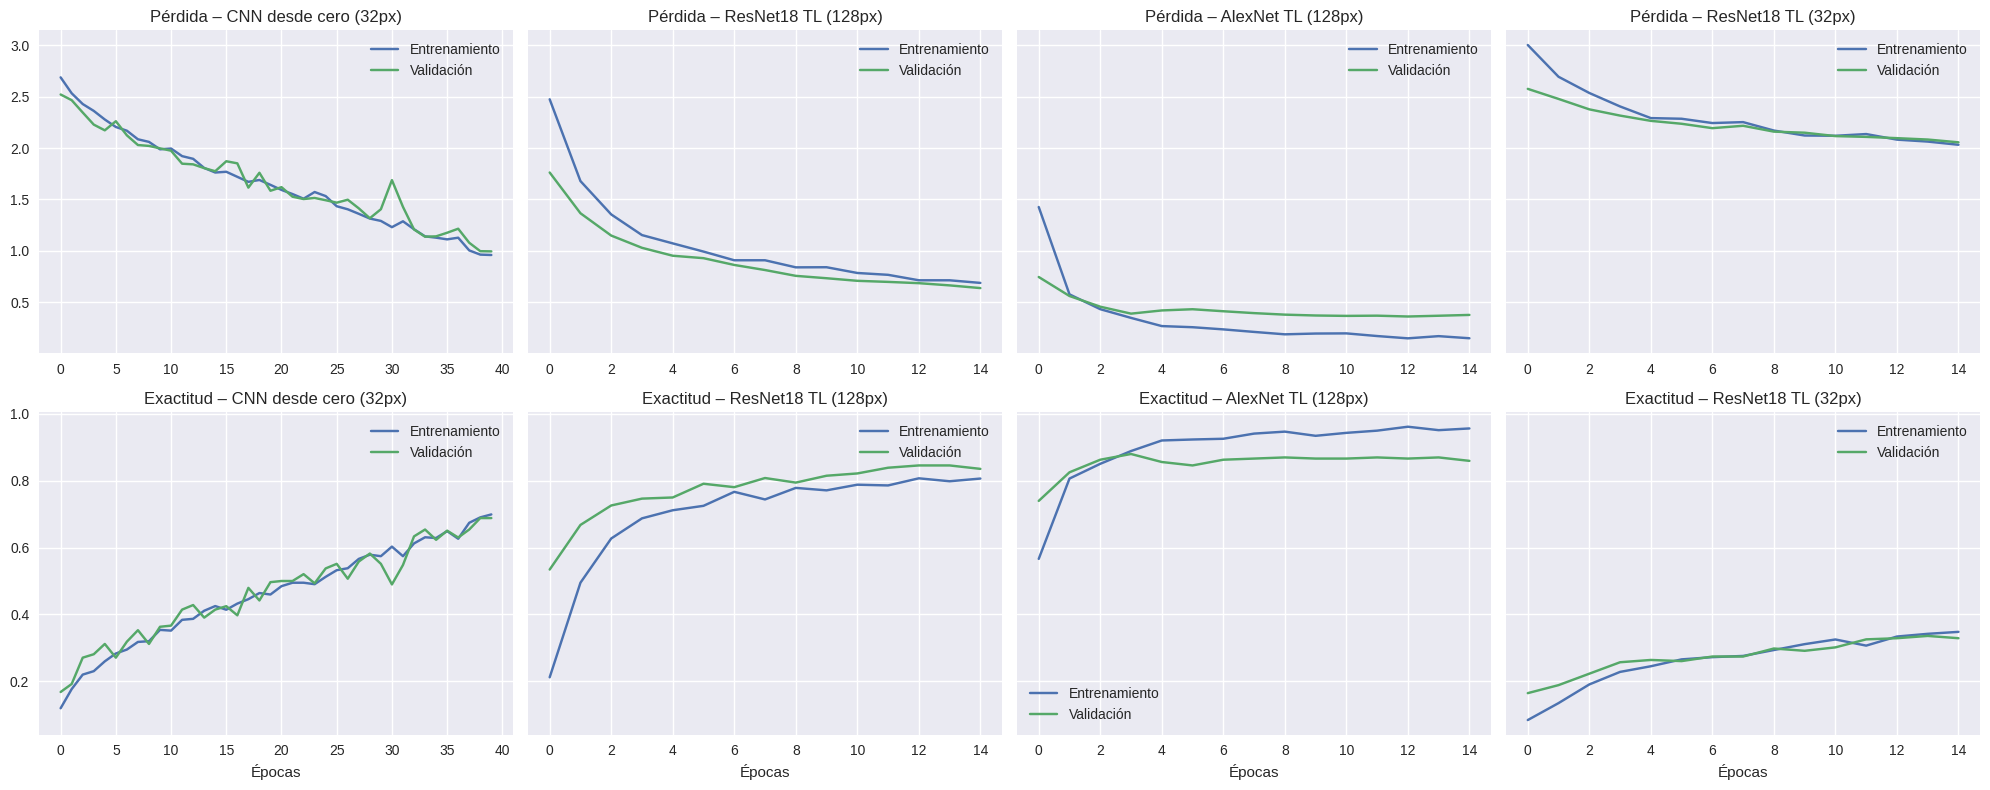

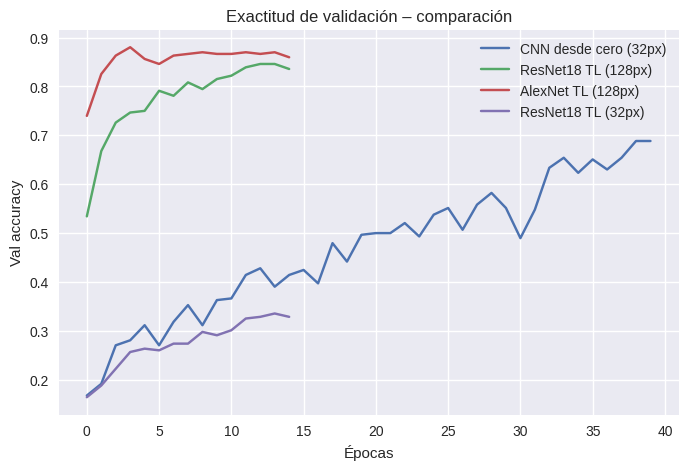

In [ ]:
#Creamos un diccionario para darles nombres a los experimentos indicando la resolución que usamos
LABELS = {'cnn': f'CNN desde cero ({CNN_IMG_SIZE}px)',
          'resnet18': f'ResNet18 TL ({TL_IMG_SIZE}px)',
          'alexnet': f'AlexNet TL ({TL_IMG_SIZE}px)',
          'resnet18_32': f'ResNet18 TL ({CNN_IMG_SIZE}px)'}
LOADERS = {'cnn': loaders_cnn, 'resnet18': loaders_tl, 'alexnet': loaders_tl, 'resnet18_32': loaders_cnn}
IMG_SIZES = {'cnn': CNN_IMG_SIZE, 'resnet18': TL_IMG_SIZE, 'alexnet': TL_IMG_SIZE, 'resnet18_32': CNN_IMG_SIZE}

fig, axes = plt.subplots(2, 4, figsize=(20, 8), sharey='row')
for j, arch in enumerate(ARCHS):
    h = histories[arch]
    axes[0, j].plot(h['train_loss'], label='Entrenamiento'); axes[0, j].plot(h['val_loss'], label='Validación')
    axes[0, j].set_title(f'Pérdida – {LABELS[arch]}')
    axes[1, j].plot(h['train_acc'], label='Entrenamiento'); axes[1, j].plot(h['val_acc'], label='Validación')
    axes[1, j].set_title(f'Exactitud – {LABELS[arch]}')
    axes[1, j].set_xlabel('Épocas')
    axes[0, j].legend(); axes[1, j].legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
for arch in ARCHS:
    plt.plot(histories[arch]['val_acc'], label=LABELS[arch])
plt.title('Exactitud de validación – comparación'); plt.xlabel('Épocas'); plt.ylabel('Val accuracy'); plt.legend()
plt.show()

**1. CNN desde cero (32px).** Muestra un aprendizaje progresivo y estable. Las pérdidas de entrenamiento y validación descienden de forma acoplada (0.9594 y 0.9947 al final) y la brecha entre la exactitud de entrenamiento (69.9 %) y la de validación (68.8 %) es mínima, por lo que no hay sobreajuste (*overfitting*) significativo. El Data Augmentation, BatchNorm y Dropout (0.5) probablemente contribuyeron a esa estabilidad, aunque no se hicieron ablaciones para comprobarlo. Hay que matizar que las métricas de entrenamiento se miden con augmentation y dropout activos, lo que las subestima, y que con ~69 % tanto en entrenamiento como en validación la limitación del modelo no es la generalización sino su capacidad y la baja resolución. Además, la mejor época fue la última (40), así que entrenar más épocas podría mejorarlo.

**2. AlexNet TL (128px) — mejor desempeño.** Es el modelo que converge más rápido: en la época 3 ya supera el 85 % de exactitud en validación. Hacia el final aparece un sobreajuste moderado: la exactitud de entrenamiento sube hasta 95.7 % mientras la de validación se mantiene en 86 a 87 %, y la pérdida de validación toca su mínimo en la época 13 (0.3608) para luego subir ligeramente. El *checkpoint* sobre la pérdida de validación permite conservar el estado de esa época; el *early stopping* no llegó a activarse porque nunca hubo 5 épocas seguidas sin mejora.

**3. ResNet18 TL (128px).** Es tan estable como AlexNet, pero de aprendizaje más gradual: la curva es suave y ascendente, la validación acompaña a la de entrenamiento sin divergir y termina en 83.6 % tras las 15 épocas. Como su pérdida de validación seguía mejorando en la última época, es probable que no haya convergido del todo y que su resultado dependa más del límite de 15 épocas que de la arquitectura.

**4. ResNet18 TL (32px) — peor desempeño.** Las curvas de exactitud se estancan en torno al 32 % tanto en entrenamiento como en validación, y la pérdida disminuye muy lentamente: es un caso claro de subajuste (*underfitting*). La causa más probable es la diferencia de escala respecto al preentrenamiento en ImageNet (~224x224): a 32x32 los objetos son diminutos y, tras las reducciones de resolución de ResNet (factor total 32), el mapa de características final es de 1x1, así que las características congeladas aportan poca información a la única capa entrenable. Los pesos preentrenados no se pierden, simplemente no resultan útiles a esta escala. Como no se probó *fine-tuning*, la conclusión es que el Transfer Learning con backbone congelado no funciona bien a 32x32, no que el modelo sea incapaz de aprender con esa resolución.

Se evaluaron los cuatro modelos con el conjunto de prueba (test). Métricas multiclase: accuracy, **balanced accuracy** y **macro-F1**, además del reporte por clase, la matriz de confusión y la curva ROC con su AUC (uno contra todos).

CNN desde cero (32px)
              precision    recall  f1-score   support

        Bear      0.619     0.722     0.667        18
        Bird      0.737     0.667     0.700        21
         Cat      0.733     0.611     0.667        18
         Cow      0.778     0.350     0.483        20
        Deer      0.542     0.684     0.605        19
         Dog      0.786     0.579     0.667        19
     Dolphin      0.857     0.947     0.900        19
    Elephant      0.750     0.750     0.750        20
     Giraffe      0.545     0.600     0.571        20
       Horse      0.786     0.550     0.647        20
    Kangaroo      0.667     0.632     0.649        19
        Lion      0.667     0.842     0.744        19
       Panda      0.850     0.850     0.850        20
       Tiger      0.706     0.632     0.667        19
       Zebra      0.529     0.857     0.655        21

    accuracy                          0.685       292
   macro avg      0.703     0.685     0.681       292
weig

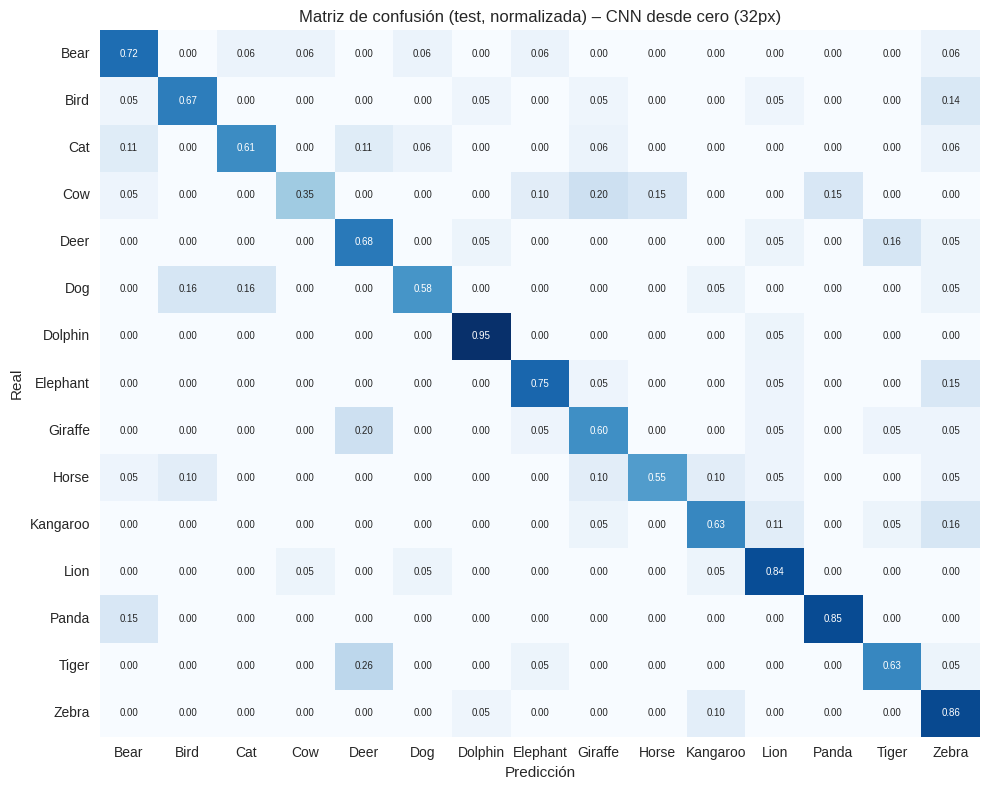

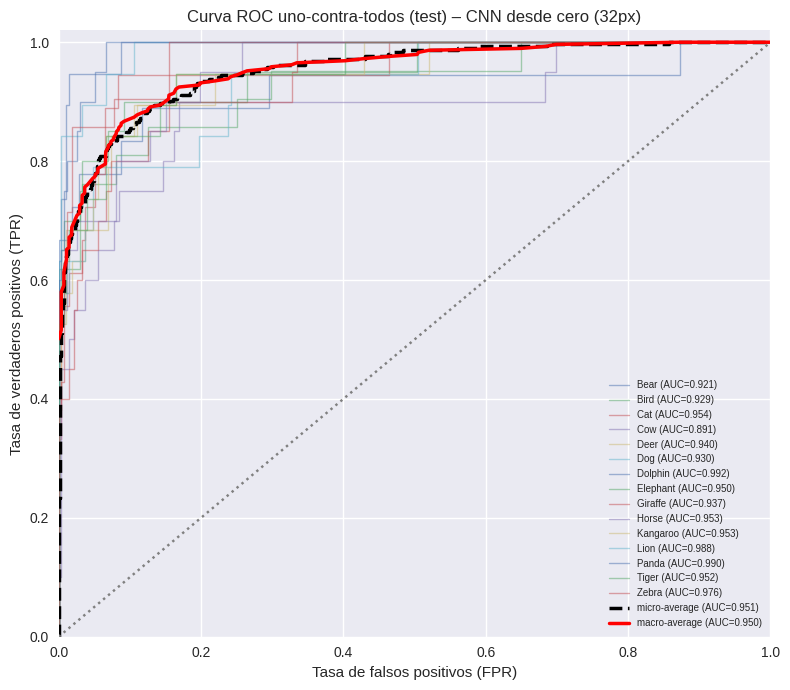

ResNet18 TL (128px)
              precision    recall  f1-score   support

        Bear      0.812     0.722     0.765        18
        Bird      0.905     0.905     0.905        21
         Cat      0.895     0.944     0.919        18
         Cow      1.000     0.900     0.947        20
        Deer      0.619     0.684     0.650        19
         Dog      0.875     0.737     0.800        19
     Dolphin      0.895     0.895     0.895        19
    Elephant      0.773     0.850     0.810        20
     Giraffe      1.000     0.700     0.824        20
       Horse      0.650     0.650     0.650        20
    Kangaroo      0.571     0.842     0.681        19
        Lion      0.722     0.684     0.703        19
       Panda      1.000     0.950     0.974        20
       Tiger      1.000     1.000     1.000        19
       Zebra      0.955     1.000     0.977        21

    accuracy                          0.832       292
   macro avg      0.845     0.831     0.833       292
weight

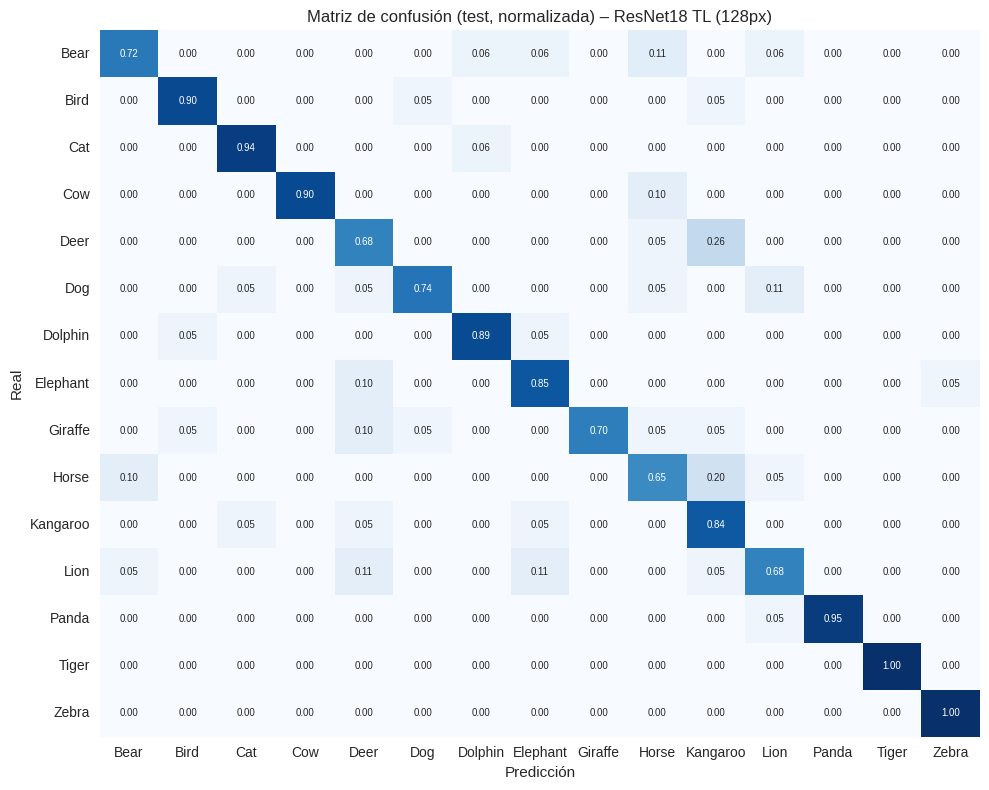

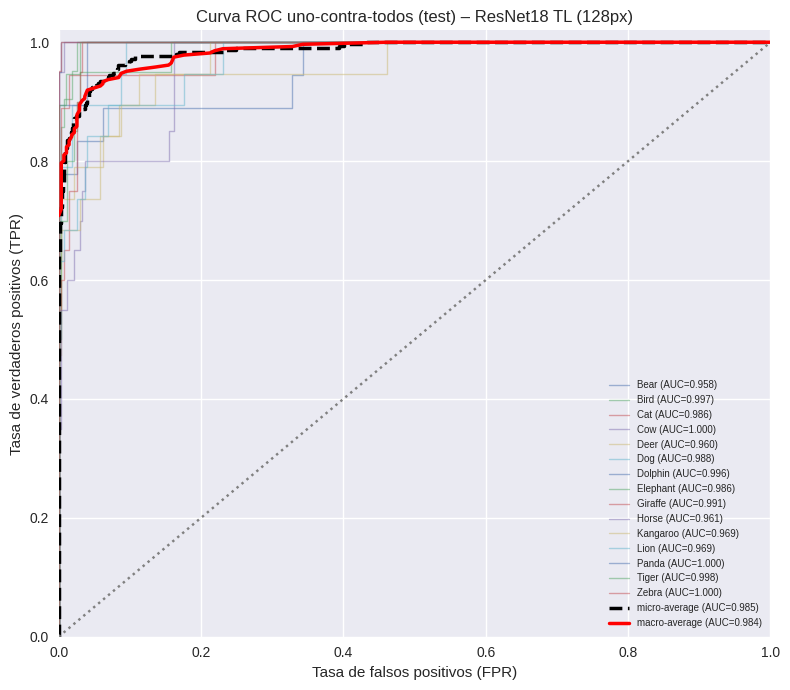

AlexNet TL (128px)
              precision    recall  f1-score   support

        Bear      0.938     0.833     0.882        18
        Bird      0.909     0.952     0.930        21
         Cat      0.778     0.778     0.778        18
         Cow      0.800     0.800     0.800        20
        Deer      0.778     0.737     0.757        19
         Dog      0.941     0.842     0.889        19
     Dolphin      1.000     0.947     0.973        19
    Elephant      0.900     0.900     0.900        20
     Giraffe      1.000     0.750     0.857        20
       Horse      0.800     0.800     0.800        20
    Kangaroo      0.720     0.947     0.818        19
        Lion      0.842     0.842     0.842        19
       Panda      0.950     0.950     0.950        20
       Tiger      0.864     1.000     0.927        19
       Zebra      0.955     1.000     0.977        21

    accuracy                          0.873       292
   macro avg      0.878     0.872     0.872       292
weighte

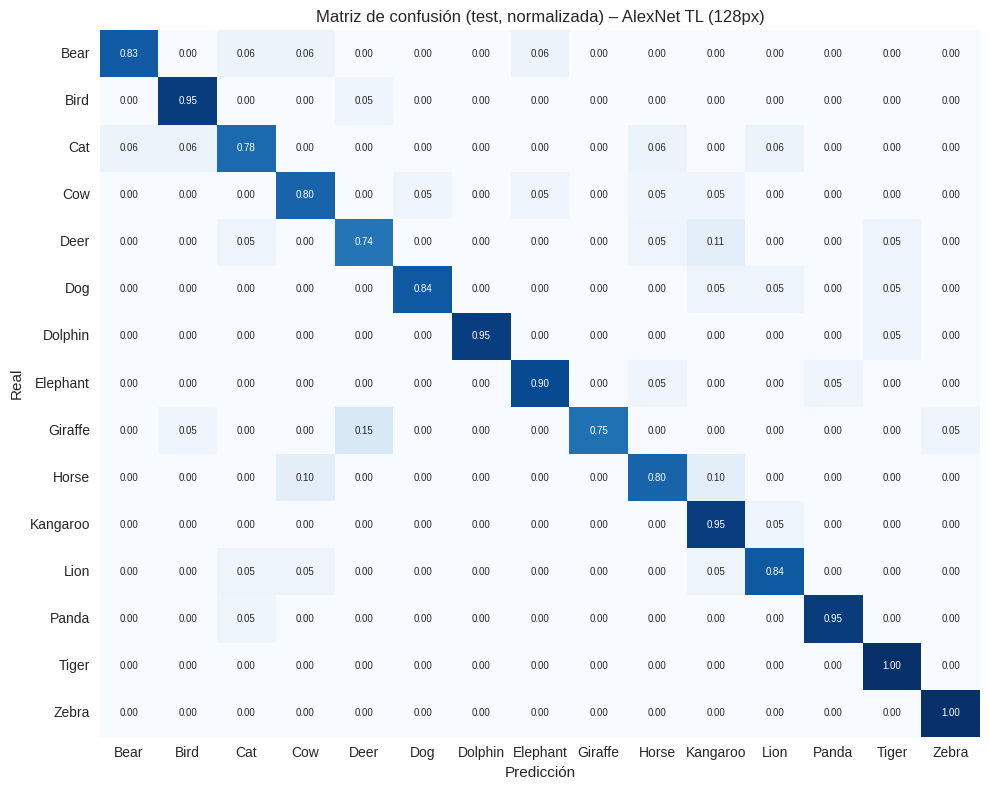

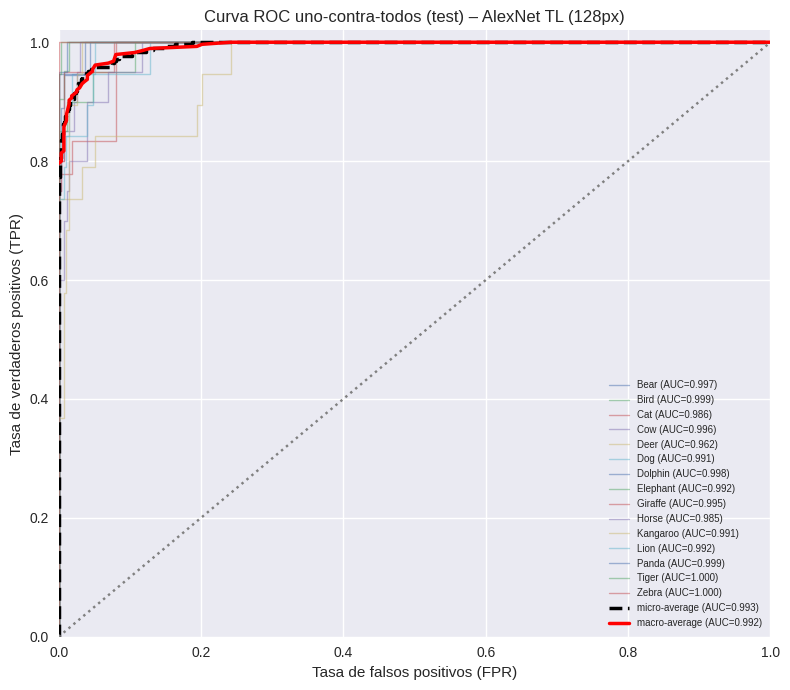

ResNet18 TL (32px)
              precision    recall  f1-score   support

        Bear      0.467     0.389     0.424        18
        Bird      0.478     0.524     0.500        21
         Cat      0.333     0.278     0.303        18
         Cow      0.312     0.250     0.278        20
        Deer      0.211     0.421     0.281        19
         Dog      0.389     0.368     0.378        19
     Dolphin      0.480     0.632     0.545        19
    Elephant      0.750     0.150     0.250        20
     Giraffe      0.200     0.400     0.267        20
       Horse      0.250     0.150     0.188        20
    Kangaroo      0.333     0.105     0.160        19
        Lion      0.120     0.158     0.136        19
       Panda      0.750     0.600     0.667        20
       Tiger      0.125     0.053     0.074        19
       Zebra      0.194     0.286     0.231        21

    accuracy                          0.318       292
   macro avg      0.359     0.318     0.312       292
weighte

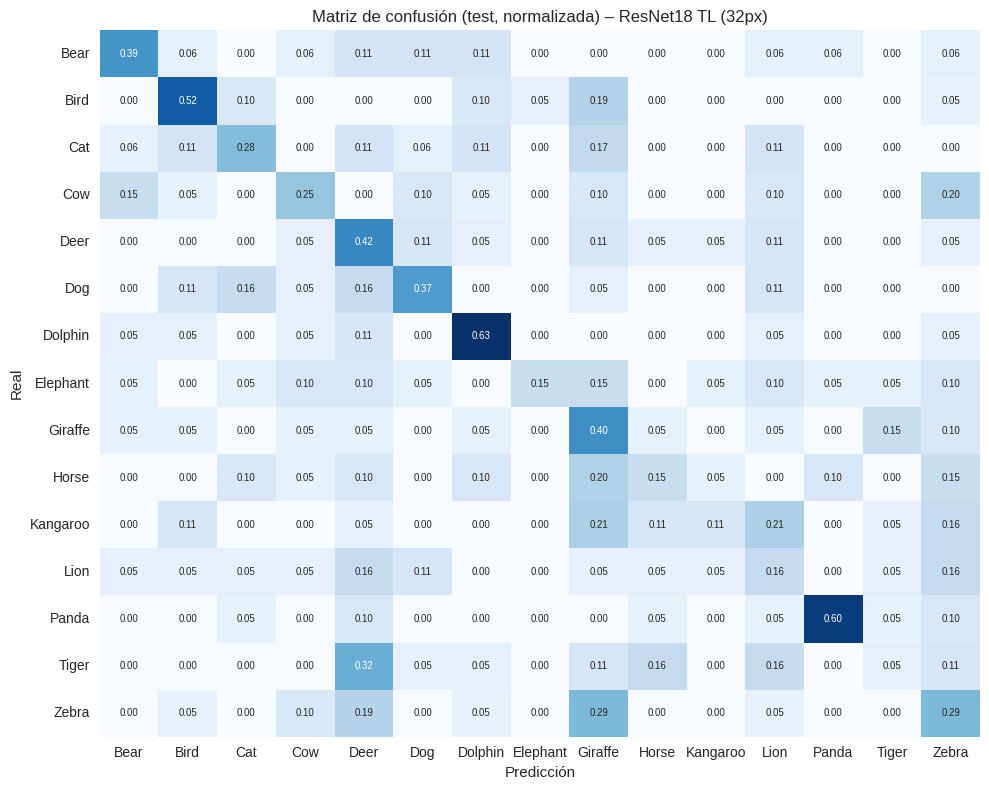

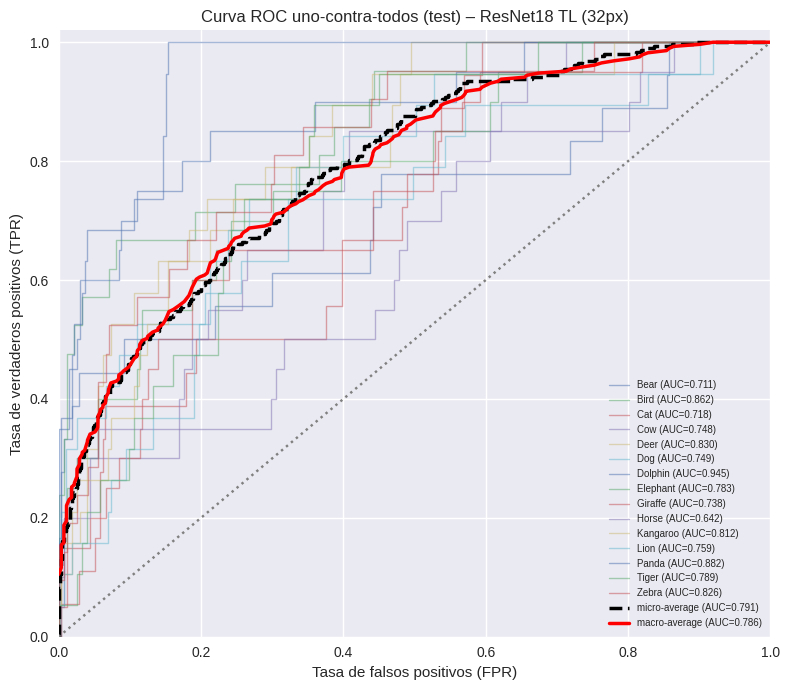

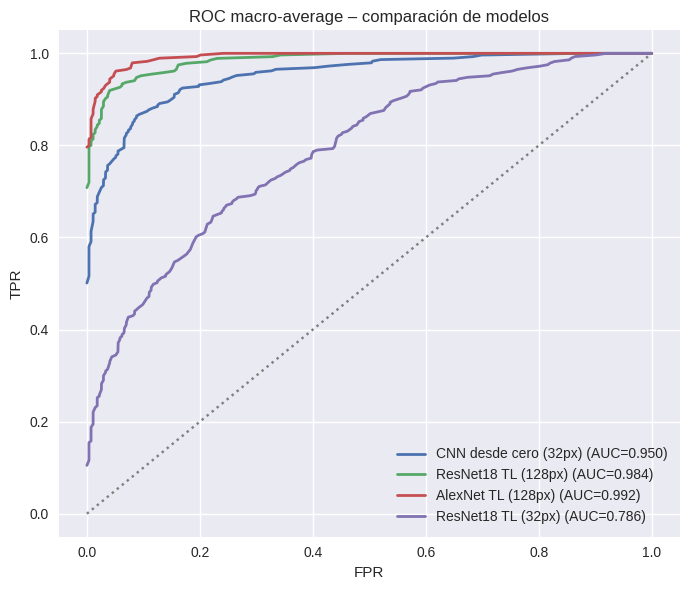

Métricas guardadas en models/metrics.json


In [ ]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize


@torch.no_grad()
def evaluate(model, loader, return_probs=False):
    model.eval()
    criterion = nn.CrossEntropyLoss(reduction='sum')
    total_loss, ys, ps, pr = 0.0, [], [], []
    if device.type == 'cuda': torch.cuda.synchronize()
    t0 = time.time()
    for x, y in loader:
        out = model(x.to(device))
        total_loss += criterion(out, y.to(device)).item()
        ys.append(y.numpy()); ps.append(out.argmax(1).cpu().numpy())
        if return_probs:
            pr.append(torch.softmax(out, dim=1).double().cpu().numpy())
    if device.type == 'cuda': torch.cuda.synchronize()
    dt = time.time() - t0
    y_true, y_pred = np.concatenate(ys), np.concatenate(ps)
    base = (total_loss / len(y_true), y_true, y_pred, 1000 * dt / len(y_true))
    return (base + (np.concatenate(pr),)) if return_probs else base


def plot_cm(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
    cm = cm.astype(float) / cm.sum(axis=1, keepdims=True)       # normalizada por fila
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', cbar=False, annot_kws={'size': 7},
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Matriz de confusión (test, normalizada) – {title}')
    plt.xlabel('Predicción'); plt.ylabel('Real')
    plt.tight_layout(); plt.show()


def compute_roc(y_true, y_prob):
    """ROC uno-contra-todos: una curva por clase + promedios micro y macro."""
    y_bin = label_binarize(y_true, classes=list(range(NUM_CLASSES)))
    fpr, tpr, roc_auc = {}, {}, {}
    for c in range(NUM_CLASSES):
        fpr[c], tpr[c], _ = roc_curve(y_bin[:, c], y_prob[:, c])
        roc_auc[c] = auc(fpr[c], tpr[c])
    fpr['micro'], tpr['micro'], _ = roc_curve(y_bin.ravel(), y_prob.ravel())
    roc_auc['micro'] = auc(fpr['micro'], tpr['micro'])
    all_fpr = np.unique(np.concatenate([fpr[c] for c in range(NUM_CLASSES)]))
    mean_tpr = np.zeros_like(all_fpr)
    for c in range(NUM_CLASSES):
        mean_tpr += np.interp(all_fpr, fpr[c], tpr[c])
    fpr['macro'], tpr['macro'] = all_fpr, mean_tpr / NUM_CLASSES
    roc_auc['macro'] = float(np.mean([roc_auc[c] for c in range(NUM_CLASSES)]))  # = roc_auc_score(ovr, macro)
    return fpr, tpr, roc_auc


def plot_roc(fpr, tpr, roc_auc, title):
    plt.figure(figsize=(8, 7))
    for c in range(NUM_CLASSES):
        plt.plot(fpr[c], tpr[c], lw=1, alpha=0.5, label=f'{class_names[c]} (AUC={roc_auc[c]:.3f})')
    plt.plot(fpr['micro'], tpr['micro'], 'k--', lw=2.5, label=f'micro-average (AUC={roc_auc["micro"]:.3f})')
    plt.plot(fpr['macro'], tpr['macro'], 'r-', lw=2.5, label=f'macro-average (AUC={roc_auc["macro"]:.3f})')
    plt.plot([0, 1], [0, 1], color='gray', ls=':')
    plt.xlim(0, 1); plt.ylim(0, 1.02)
    plt.xlabel('Tasa de falsos positivos (FPR)'); plt.ylabel('Tasa de verdaderos positivos (TPR)')
    plt.title(f'Curva ROC uno-contra-todos (test) – {title}')
    plt.legend(fontsize=7, loc='lower right')
    plt.tight_layout(); plt.show()


def _json_default(o):
    if isinstance(o, np.generic): return o.item()
    if isinstance(o, np.ndarray): return o.tolist()
    raise TypeError(f'No serializable: {type(o)}')


rows, preds, roc_store = [], {}, {}
metrics_json = {
    'classes': class_names,
    'split_sizes': {'train': len(train_idx), 'val': len(val_idx), 'test': len(test_idx)},
    'models': {},
}

for arch in ARCHS:
    test_loss, y_true, y_pred, ms_img, y_prob = evaluate(trained[arch], LOADERS[arch]['test'], return_probs=True)
    preds[arch] = (y_true, y_pred)
    total, trainable = count_params(trained[arch])
    fpr, tpr, roc_auc = compute_roc(y_true, y_prob)
    roc_store[arch] = (fpr, tpr, roc_auc)

    acc = accuracy_score(y_true, y_pred)
    bal = balanced_accuracy_score(y_true, y_pred)
    f1m = f1_score(y_true, y_pred, average='macro')
    rows.append({
        'Modelo': LABELS[arch], 'Entrada (px)': IMG_SIZES[arch],
        'Params totales': total, 'Params entrenables': trainable,
        'Épocas': len(histories[arch]['val_loss']), 'Tiempo entrenamiento (s)': round(train_times[arch], 1),
        'Test loss': round(test_loss, 4),
        'Accuracy': round(acc, 4), 'Balanced Acc': round(bal, 4), 'Macro-F1': round(f1m, 4),
        'ROC AUC (macro)': round(roc_auc['macro'], 4), 'ROC AUC (micro)': round(roc_auc['micro'], 4),
        'ms/imagen': round(ms_img, 2),
    })

    report = classification_report(y_true, y_pred, target_names=class_names, digits=3,
                                   zero_division=0, output_dict=True)
    print('=' * 80); print(LABELS[arch])
    print(classification_report(y_true, y_pred, target_names=class_names, digits=3, zero_division=0))
    plot_cm(y_true, y_pred, LABELS[arch])
    plot_roc(fpr, tpr, roc_auc, LABELS[arch])

    # ---- métricas de este modelo para el JSON (se mostrarán en la app) ----
    metrics_json['models'][arch] = {
        'label': LABELS[arch], 'img_size': IMG_SIZES[arch],
        'params_total': total, 'params_trainable': trainable,
        'epochs': len(histories[arch]['val_loss']), 'train_time_s': round(train_times[arch], 1),
        'ms_per_image': round(ms_img, 3),
        'test': {'loss': round(test_loss, 4), 'accuracy': round(acc, 4), 'balanced_accuracy': round(bal, 4),
                 'macro_f1': round(f1m, 4), 'roc_auc_macro': round(roc_auc['macro'], 4),
                 'roc_auc_micro': round(roc_auc['micro'], 4)},
        'per_class': {cls: {'precision': report[cls]['precision'], 'recall': report[cls]['recall'],
                            'f1': report[cls]['f1-score'], 'support': report[cls]['support'],
                            'auc': round(roc_auc[c], 4)} for c, cls in enumerate(class_names)},
        'confusion_matrix': confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES)),   # conteos
        'roc': {k: {'fpr': np.round(fpr[k], 4), 'tpr': np.round(tpr[k], 4), 'auc': round(roc_auc[k], 4)}
                for k in ['micro', 'macro']},
        'roc_per_class': {cls: {'fpr': np.round(fpr[c], 4), 'tpr': np.round(tpr[c], 4)}
                          for c, cls in enumerate(class_names)},
        'history': histories[arch],     # loss y accuracy por época (train / val)
    }

results_df = pd.DataFrame(rows).set_index('Modelo')

# Comparación de curvas ROC (promedio macro) entre los cuatro modelos
plt.figure(figsize=(7, 6))
for arch in ARCHS:
    fpr, tpr, roc_auc = roc_store[arch]
    plt.plot(fpr['macro'], tpr['macro'], lw=2, label=f'{LABELS[arch]} (AUC={roc_auc["macro"]:.3f})')
plt.plot([0, 1], [0, 1], color='gray', ls=':')
plt.xlabel('FPR'); plt.ylabel('TPR'); plt.title('ROC macro-average – comparación de modelos')
plt.legend(loc='lower right'); plt.tight_layout(); plt.show()

# Guardar todas las métricas en un JSON
with open(os.path.join(MODELS_DIR, 'metrics.json'), 'w', encoding='utf-8') as f:
    json.dump(metrics_json, f, ensure_ascii=False, indent=2, default=_json_default)
print('Métricas guardadas en', os.path.join(MODELS_DIR, 'metrics.json'))

**AlexNet TL (128px):** 87.33 % de exactitud y 87.20 % de Macro-F1 (255 aciertos y 37 errores sobre 292 imágenes), con el mayor AUC macro (0.992) y la menor pérdida en test (0.436). Es una arquitectura antigua, pero un clasificador lineal sobre sus características preentrenadas, con imágenes de 128px, rinde muy bien.

**ResNet18 TL (128px):** 83.22 % de exactitud, 83.32 % de Macro-F1 y AUC macro de 0.984 (243 aciertos, 12 menos que AlexNet). Tiene 11 millones de parámetros frente a los 57 de AlexNet, por lo que es mucho más ligera en memoria y disco, aunque su tiempo de inferencia por imagen es casi el mismo (1.87 ms frente a 1.93 ms).

**CNN desde cero (32px):** 68.49 % de exactitud y 68.13 % de Macro-F1 (AUC macro 0.950). A 32x32, donde se pierde casi todo el detalle fino, es un resultado razonable para una red de 4 bloques convolucionales con Batch Normalization y Dropout, aunque queda lejos de los modelos a 128px.

**ResNet18 TL (32px):** 31.85 % de exactitud (unas 4.8 veces el azar, que es 6.7 %) y AUC macro de 0.786. Aprende algo, pero muy poco: sus filtros se preentrenaron con imágenes de ~224x224 y, con el extractor congelado y entradas de 32x32, las características que llegan a la capa final aportan poca información.

## 11. Comparación de los modelos

Se realizó una comparación visual y cuantitativa del rendimiento de los cuatro modelos, evaluados con el conjunto de prueba (test).

Se muestra la tabla de resultados (`display(results_df)`) y un gráfico de barras generado con matplotlib que compara cuatro métricas esenciales para cada modelo: accuracy, balanced accuracy, macro-F1 y ROC AUC (macro).

,Entrada (px),Params totales,Params entrenables,Épocas,Tiempo entrenamiento (s),Test loss,Accuracy,Balanced Acc,Macro-F1,ROC AUC (macro),ROC AUC (micro),ms/imagen
Modelo,,,,,,,,,,,,
CNN desde cero (32px),32,459535,459535,40,99.4,1.0903,0.6849,0.6849,0.6813,0.9504,0.9510,1.27
ResNet18 TL (128px),128,11184207,7695,15,58.8,0.6543,0.8322,0.8309,0.8332,0.9839,0.9851,1.87
AlexNet TL (128px),128,57065295,61455,15,58.6,0.4357,0.8733,0.8720,0.8720,0.9921,0.9927,1.93
ResNet18 TL (32px),32,11184207,7695,15,36.0,2.1375,0.3185,0.3175,0.3121,0.7864,0.7908,2.13


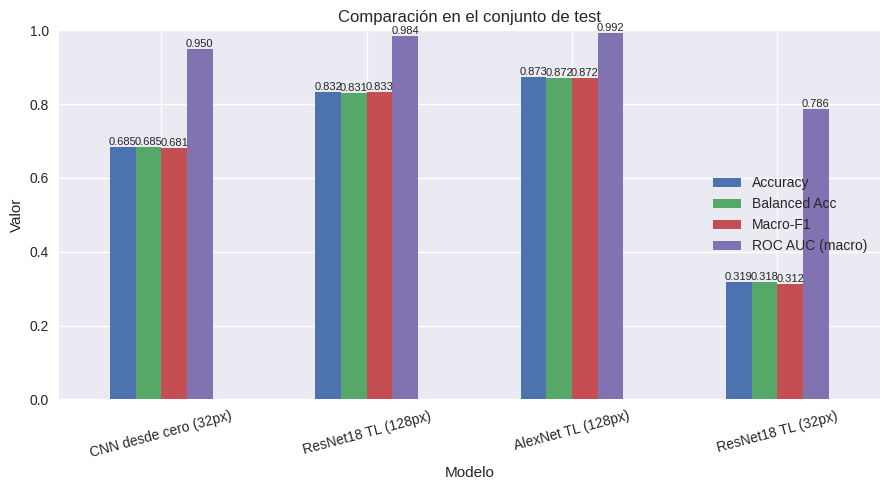

Mejor modelo según Macro-F1: AlexNet TL (128px)


In [ ]:
display(results_df)

metrics = ['Accuracy', 'Balanced Acc', 'Macro-F1', 'ROC AUC (macro)']
ax = results_df[metrics].plot(kind='bar', figsize=(9, 5), rot=15)
ax.set_title('Comparación en el conjunto de test'); ax.set_ylim(0, 1); ax.set_ylabel('Valor')
for c in ax.containers: ax.bar_label(c, fmt='%.3f', fontsize=8)
plt.tight_layout(); plt.show()

best_label = results_df['Macro-F1'].idxmax()
best_arch = [a for a, l in LABELS.items() if l == best_label][0]
print(f'Mejor modelo según Macro-F1: {best_label}')

**AlexNet TL (128px)** obtuvo el mejor resultado en todas las métricas de test (exactitud 87.33 %, Macro-F1 87.20 %, AUC macro 0.992). Su ventaja sobre ResNet18 (128px) es de 4.11 puntos porcentuales de exactitud, es decir, 12 imágenes más acertadas de 292. La ventaja es consistente entre métricas, pero con un conjunto de test tan pequeño conviene considerarla moderada y no concluyente por sí sola.

### Comparación a igual resolución (32x32)
CNN desde cero vs. ResNet18 con Transfer Learning entrenados con las mismas imágenes de 32x32, frente a ResNet18 a 128x128. Permite separar el efecto del preentrenamiento del efecto de la resolución.

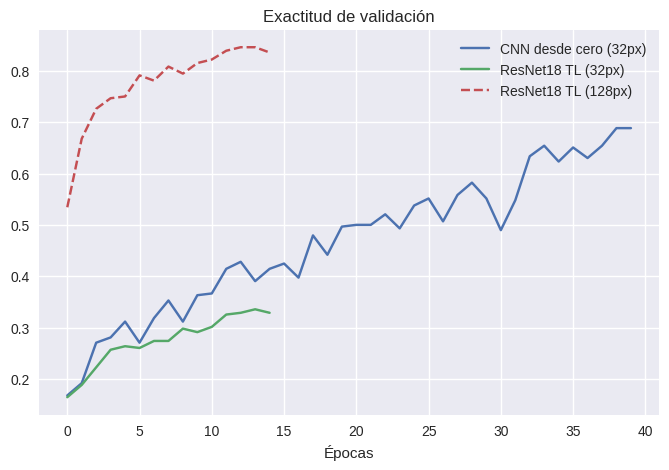

In [ ]:
# Misma resolución (32px): CNN desde cero vs ResNet18 TL
plt.figure(figsize=(8, 5))
plt.plot(histories['cnn']['val_acc'], label='CNN desde cero (32px)')
plt.plot(histories['resnet18_32']['val_acc'], label='ResNet18 TL (32px)')
plt.plot(histories['resnet18']['val_acc'], '--', label='ResNet18 TL (128px)')
plt.title('Exactitud de validación'); plt.xlabel('Épocas'); plt.legend(); plt.show()

Al analizar los dos modelos entrenados estrictamente con imágenes de 32x32 píxeles, nos dimos cuenta de que la CNN desde cero supera con claridad a ResNet18 TL.

- **CNN desde cero (32px):** alcanza 68.49 % de exactitud en el conjunto de test.
- **ResNet18 TL (32px):** se queda rezagada, con apenas 31.85 % de exactitud (unas 4.8 veces el azar, que es 6.7 %).

Esto ocurrió porque los filtros convolucionales de ResNet18 fueron preentrenados en ImageNet con imágenes de ~224x224 píxeles. Al congelar el extractor de características (*backbone*) y forzarlo a procesar entradas de 32x32, el cambio de escala hace que las características que llegan a la capa final aporten poca información. Como solo se entrena la última capa lineal (7,695 parámetros), el modelo no puede compensarlo y sufre un subajuste (*underfitting*) marcado. La CNN, en cambio, ajusta sus 459,535 parámetros directamente sobre las imágenes de 32x32. Esta conclusión corresponde a un backbone congelado; no se probó *fine-tuning*.

Errores de AlexNet TL (128px): 37 de 292


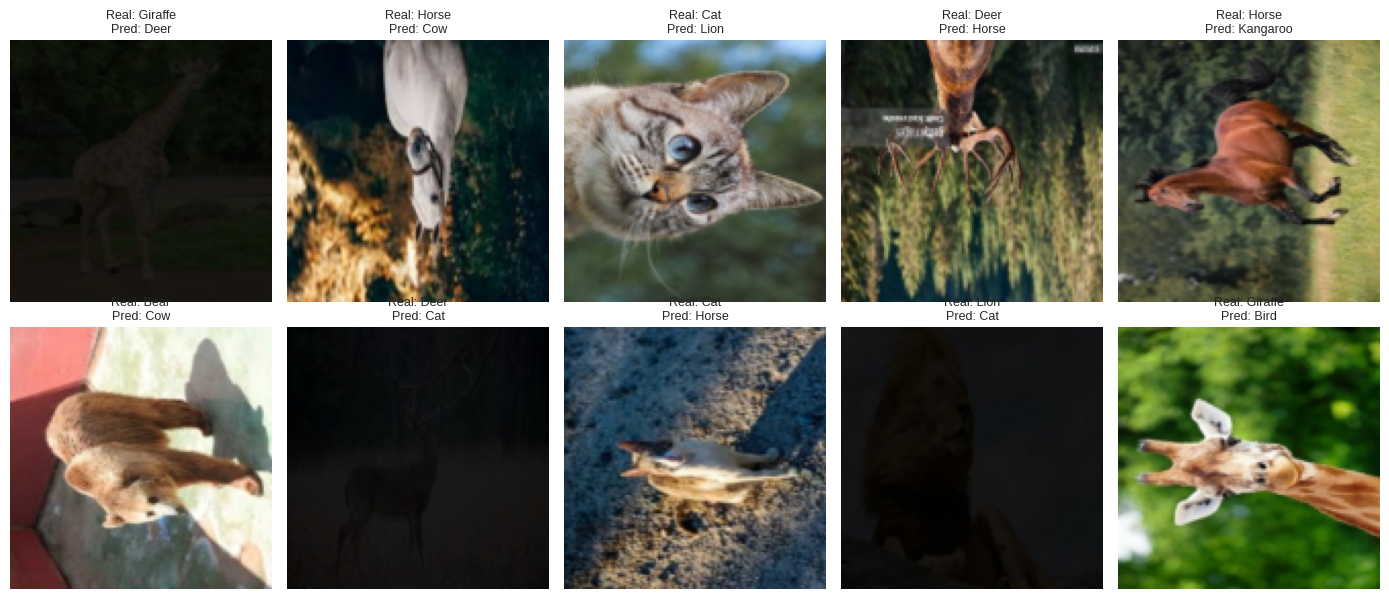

In [ ]:
# Ejemplos mal clasificados por el mejor modelo
y_true, y_pred = preds[best_arch]
wrong = np.where(y_true != y_pred)[0]
print(f'Errores de {LABELS[best_arch]}: {len(wrong)} de {len(y_true)}')

mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1); std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
test_ds = LOADERS[best_arch]['test'].dataset
show = wrong[:10]
if len(show):
    fig, axes = plt.subplots(2, 5, figsize=(14, 6))
    for ax in axes.reshape(-1): ax.axis('off')
    for ax, i in zip(axes.reshape(-1), show):
        x, _ = test_ds[i]
        ax.imshow((x * std + mean).clamp(0, 1).permute(1, 2, 0).numpy())
        ax.set_title(f'Real: {class_names[y_true[i]]}\nPred: {class_names[y_pred[i]]}', fontsize=9)
    plt.tight_layout(); plt.show()

## 12. Guardado de los modelos y configuración para la app
Los mejores pesos de cada modelo ya se guardaron durante el entrenamiento en `models/*.pth` (como `state_dict`).
Además se genera `models/model_config.json` con las **clases**, la normalización, el tamaño de entrada de cada modelo y sus métricas,
que la app NNApp leerá para preprocesar cualquier imagen igual que en el entrenamiento.

In [ ]:
config = {
    'classes': class_names,
    'mean': IMAGENET_MEAN,
    'std': IMAGENET_STD,
    'models': {}
}
for arch in ARCHS:
    r = results_df.loc[LABELS[arch]]
    config['models'][arch] = {
        'label': LABELS[arch],
        'weights': f'{arch}.pth',
        'img_size': IMG_SIZES[arch],
        'test_accuracy': float(r['Accuracy']),
        'test_balanced_accuracy': float(r['Balanced Acc']),
        'test_macro_f1': float(r['Macro-F1']),
    }
with open(os.path.join(MODELS_DIR, 'model_config.json'), 'w', encoding='utf-8') as f:
    json.dump(config, f, indent=2, ensure_ascii=False)

shutil.copy('model_defs.py', os.path.join(MODELS_DIR, 'model_defs.py'))   # misma arquitectura para la app
print(sorted(os.listdir(MODELS_DIR)))
print(json.dumps(config['models'], indent=2, ensure_ascii=False))

['alexnet.pth', 'cnn.pth', 'metrics.json', 'model_config.json', 'model_defs.py', 'resnet18.pth', 'resnet18_32.pth']
{
  "cnn": {
    "label": "CNN desde cero (32px)",
    "weights": "cnn.pth",
    "img_size": 32,
    "test_accuracy": 0.6849,
    "test_balanced_accuracy": 0.6849,
    "test_macro_f1": 0.6813
  },
  "resnet18": {
    "label": "ResNet18 TL (128px)",
    "weights": "resnet18.pth",
    "img_size": 128,
    "test_accuracy": 0.8322,
    "test_balanced_accuracy": 0.8309,
    "test_macro_f1": 0.8332
  },
  "alexnet": {
    "label": "AlexNet TL (128px)",
    "weights": "alexnet.pth",
    "img_size": 128,
    "test_accuracy": 0.8733,
    "test_balanced_accuracy": 0.872,
    "test_macro_f1": 0.872
  },
  "resnet18_32": {
    "label": "ResNet18 TL (32px)",
    "weights": "resnet18_32.pth",
    "img_size": 32,
    "test_accuracy": 0.3185,
    "test_balanced_accuracy": 0.3175,
    "test_macro_f1": 0.3121
  }
}


## 13. Verificación: cargar los pesos desde disco y clasificar una imagen cualquiera
Esto es exactamente lo que hará la app: reconstruir la arquitectura (`pretrained=False`, no hace falta descargar nada),
cargar el `.pth`, aplicar el mismo preprocesamiento y predecir.

CNN desde cero (32px)        accuracy recargado: 0.6849 (entrenado: 0.6849)
ResNet18 TL (128px)          accuracy recargado: 0.8322 (entrenado: 0.8322)
AlexNet TL (128px)           accuracy recargado: 0.8733 (entrenado: 0.8733)
ResNet18 TL (32px)           accuracy recargado: 0.3185 (entrenado: 0.3185)


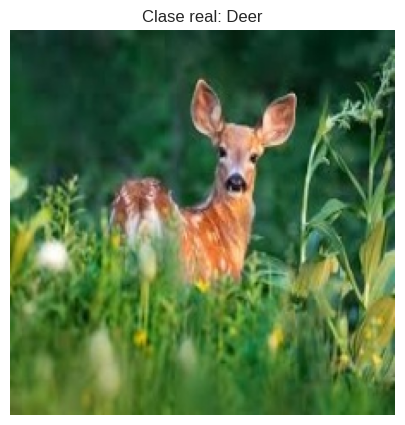

CNN desde cero (32px) -> [('Deer', '67.32%'), ('Giraffe', '24.38%'), ('Tiger', '3.56%')]
ResNet18 TL (128px) -> [('Deer', '62.36%'), ('Dog', '7.24%'), ('Bird', '6.89%')]
AlexNet TL (128px) -> [('Deer', '51.34%'), ('Giraffe', '36.76%'), ('Horse', '9.02%')]
ResNet18 TL (32px) -> [('Giraffe', '22.24%'), ('Deer', '15.73%'), ('Zebra', '13.09%')]


In [ ]:
_loaded = {}
def load_trained(arch):
    if arch not in _loaded:
        m = build_model(arch, len(config['classes']), pretrained=False)
        m.load_state_dict(torch.load(os.path.join(MODELS_DIR, config['models'][arch]['weights']), map_location=device))
        _loaded[arch] = m.to(device).eval()
    return _loaded[arch]


def predict_image(img, arch, topk=3):
    cfg = config['models'][arch]
    tf = transforms.Compose([
        transforms.Resize((cfg['img_size'], cfg['img_size'])),
        transforms.ToTensor(),
        transforms.Normalize(config['mean'], config['std'])])
    x = tf(img.convert('RGB')).unsqueeze(0).to(device)
    with torch.no_grad():
        probs = torch.softmax(load_trained(arch)(x), dim=1)[0]
    top = probs.topk(min(topk, len(config['classes'])))
    return [(config['classes'][i], float(p)) for p, i in zip(top.values.cpu(), top.indices.cpu())]


# 1) Los modelos recargados deben reproducir la accuracy de test
for arch in ARCHS:
    _, yt, yp, _ = evaluate(load_trained(arch), LOADERS[arch]['test'])
    print(f'{LABELS[arch]:28s} accuracy recargado: {accuracy_score(yt, yp):.4f} (entrenado: {config["models"][arch]["test_accuracy"]:.4f})')

# 2) Clasificar una imagen de test con los cuatro modelos
k = random.choice(list(test_idx))
img_path, real = full_ds.samples[k]
img = Image.open(img_path)
plt.imshow(img.convert('RGB')); plt.axis('off'); plt.title(f'Clase real: {class_names[real]}'); plt.show()
for arch in ARCHS:
    print(LABELS[arch], '->', [(c, f'{p:.2%}') for c, p in predict_image(img, arch)])

In [ ]:
# Descargar los pesos si se ejecuta desde Google Colab
try:
    from google.colab import files
    shutil.make_archive('nnapp_models', 'zip', MODELS_DIR)
    files.download('nnapp_models.zip')
except ImportError:
    print('Fuera de Colab: los archivos están en la carpeta', os.path.abspath(MODELS_DIR))

Confirmamos que al reconstruir las arquitecturas desde cero y recargar los pesos guardados en los archivos .pth, el rendimiento en el conjunto de prueba es exactamente el mismo que durante la etapa de evaluación. Las precisiones recargadas coinciden al 100 % con las originales.

En esta ejecución se usó una imagen real de un Ciervo (Deer). Los tres primeros modelos acertaron la clase (CNN 67.3 %, ResNet18 128px 62.4 % y AlexNet 51.3 %), mientras que ResNet18 a 32px falló (predijo Giraffe con 22.2 %). Es un único ejemplo, así que la confianza no sirve para ordenar los modelos.

## 14. Análisis y conclusiones


### 1. Modelo con mejor rendimiento
El mejor modelo en todas las métricas de test fue **AlexNet TL (128px)**: **87.33 % de Accuracy**, **87.20 % de Macro-F1** y **AUC macro de 0.992**, con 37 errores sobre 292 imágenes. El segundo fue **ResNet18 TL (128px)** (83.22 % de Accuracy, 83.32 % de Macro-F1 y AUC macro de 0.984). La diferencia es de **4.11 puntos porcentuales** (12 imágenes) y es consistente entre métricas, pero con un test de 292 imágenes, una sola partición y una sola ejecución no basta para afirmar una superioridad definitiva.

### 2. CNN desde cero vs. Transfer Learning
* **Resolución:** al reducir a 32x32 se pierde buena parte del detalle fino (textura, plumas, pelaje), lo que probablemente obliga a los modelos a apoyarse más en siluetas gruesas y colores dominantes.
* **ResNet18 TL a 32px:** obtuvo **31.85 % de exactitud** (unas 4.8 veces el azar) y un AUC macro de 0.786: aprende algo, pero muy poco. Los filtros preentrenados a ~224x224 aportan características poco informativas con entradas de 32x32, y solo se entrena la capa final.
* **CNN desde cero (32px):** al entrenar el 100 % de sus parámetros logró **68.49 %**. En este experimento (backbone congelado, 32x32) una red simple entrenada desde cero supera con claridad al Transfer Learning. No se probó *fine-tuning*, así que no se puede extender a todo Transfer Learning.
* A 128px el Transfer Learning supera con claridad a la CNN, pero esa comparación mezcla resolución y preentrenamiento (ver propuesta 3).

### 3. ResNet18 vs. AlexNet
* **Parámetros:** AlexNet tiene **57,065,295** parámetros totales y ResNet18 **11,184,207** (5 veces menos). En la capa de clasificación, ResNet18 entrena **7,695** y AlexNet **61,455**.
* **Despliegue:** ResNet18 ocupa mucho menos disco y memoria, pero su velocidad de inferencia por imagen es casi la misma (1.87 ms frente a 1.93 ms). Es un compromiso: AlexNet ofrece 4.1 puntos más de exactitud y ResNet18 es más ligera, así que la elección depende de si se prioriza precisión o tamaño.

### 4. Análisis de curvas y sobreajuste
* **CNN (32px):** curvas acopladas (entrenamiento 69.9 %, validación 68.8 %, test 68.5 %), sin sobreajuste. El mejor modelo fue el de la última época y la pérdida seguía bajando, así que entrenar más podría mejorarlo.
* **AlexNet (128px):** sobreajuste moderado. La exactitud de entrenamiento sube hasta 95.7 % mientras la de validación se mantiene en 86 a 87 %, y la pérdida de validación toca su mínimo en la época 13 (0.361) y luego sube. Se conservó el *checkpoint* de esa época; el *early stopping* no llegó a activarse en ningún modelo.
* **ResNet18 (128px):** sin sobreajuste (entrenamiento 80.7 %, validación 83.6 %). La pérdida de validación seguía mejorando en la época 15, así que no había convergido.
* **ResNet18 (32px):** subajuste (entrenamiento 34.8 %, validación 32.9 %): el modelo no logra extraer información útil.
* Las métricas de entrenamiento se miden con augmentation y dropout activos, por lo que subestiman el rendimiento real.

### 5. Matriz de confusión y errores
* **Mejor reconocidas:** **Tiger** y **Zebra** (100 % de recall en ResNet18 y AlexNet) y **Panda** (95 %), probablemente por sus patrones distintivos (rayas y manchas).
* **Más difíciles:** **Deer** y **Horse** (F1 de 0.650 y 0.650 en ResNet18; 0.757 y 0.800 en AlexNet), que suelen predecirse como **Kangaroo** (en ResNet18: Deer→Kangaroo 26 %, Horse→Kangaroo 20 %). En AlexNet destacan Giraffe→Deer (15 %) y Horse→Cow (10 %). La CNN a 32px confunde más ampliamente (Tiger→Deer 26 %, Giraffe→Deer 20 %, Cow→Giraffe 20 %, con solo 35 % de recall en Cow). Una posible causa son los colores y fondos parecidos (pasto o tierra).